In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

folder = r"C:\Users\sujat\OneDrive\Desktop\Retail-Inv-opt"

csv_path = folder + r"\online_retail_II.csv"

# first run only: convert the Excel file to CSV (takes a few minutes)
if not os.path.exists(csv_path):
    sheets = pd.read_excel(
        folder + r"\online_retail_II.xlsx",
        sheet_name=None,
        dtype={"StockCode": str, "Invoice": str},
    )
    pd.concat(sheets.values(), ignore_index=True).to_csv(csv_path, index=False)

# load the data
df = pd.read_csv(csv_path,
                 parse_dates=["InvoiceDate"],
                 dtype={"StockCode": str, "Invoice": str})

print(df.shape)  # expect (1067371, 8)
df.info()
display(df.head())

(1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
# checking size and structure of the data
print("Shape:", df.shape)
df.info()

Shape: (1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [3]:
# which columns have nulls
print(df.isna().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [4]:
# duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


In [5]:
# cancelled invoices start with 'C'
cancelled = df["Invoice"].astype(str).str.startswith("C").sum()
print("Cancelled invoices:", cancelled)

# negative or zero quantity / price
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

Cancelled invoices: 19494
Quantity <= 0: 22950
Price <= 0: 6207


In [6]:
# time period covered
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

# number of unique products and invoices
print("Unique SKUs:", df["StockCode"].nunique())
print("Unique invoices:", df["Invoice"].nunique())

Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique SKUs: 5305
Unique invoices: 53628


In [7]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [8]:
# codes like postage, bank charges, manual entries are not real products
non_product = df[df["StockCode"].astype(str).str.match(
    r"^(POST|DOT|M$|BANK CHARGES|C2|AMAZONFEE|ADJUST|S$|B$|CRUK|D$|TEST)", na=False)]

print(non_product["StockCode"].value_counts())

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
CRUK              16
TEST001           15
B                  6
ADJUST2            3
TEST002            2
Name: count, dtype: int64


In [9]:
# work on a copy so raw df stays safe
data = df.copy()
print("Start:", len(data))

data = data.drop_duplicates()
print("After duplicates:", len(data))

Start: 1067371
After duplicates: 1033036


In [10]:
# invoices starting with 'C' are cancelled
data = data[~data["Invoice"].astype(str).str.startswith("C")]
print("After cancellations:", len(data))

After cancellations: 1013932


In [11]:
data = data[(data["Quantity"] > 0) & (data["Price"] > 0)]
print("After bad qty/price:", len(data))

After bad qty/price: 1007913


In [12]:
# postage, fees, adjustments etc. are not real products
non_product_codes = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES",
                     "ADJUST", "ADJUST2", "AMAZONFEE", "CRUK", "B",
                     "TEST001", "TEST002", "PADS"]

data = data[~data["StockCode"].isin(non_product_codes)]
print("After non-product codes:", len(data))

After non-product codes: 1003422


In [13]:
# codes with no digits can still be non-products
odd = data[~data["StockCode"].str.contains(r"\d", regex=True)]
print(odd["StockCode"].value_counts())

# gift vouchers
print("Gift voucher rows:", data["StockCode"].str.lower().str.startswith("gift").sum())

StockCode
DCGSSGIRL    23
DCGSSBOY     21
m             5
Name: count, dtype: int64
Gift voucher rows: 77


In [14]:
data["Revenue"] = data["Quantity"] * data["Price"]

# biggest quantities, to spot outliers
data.sort_values("Quantity", ascending=False).head(10)[
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "InvoiceDate"]]

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,2010-02-15 11:57:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,2010-03-17 13:09:00
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,2010-03-17 13:09:00
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,2010-03-17 13:09:00
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2010-03-23 15:36:00
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2010-03-23 15:36:00
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,2010-03-23 15:36:00


In [15]:
# two huge orders that were cancelled later (cancel rows already dropped)
data = data[~data["Quantity"].isin([80995, 74215])]
print("After outlier orders:", len(data))

# gift vouchers and lowercase 'm' are not products
data = data[~data["StockCode"].str.lower().str.startswith("gift")]
data = data[data["StockCode"] != "m"]
print("After vouchers and m:", len(data))

After outlier orders: 1003420
After vouchers and m: 1003338


In [16]:
data = data.reset_index(drop=True)
data.to_csv(folder + r"\online_retail_clean.csv", index=False)
print("Clean shape:", data.shape)

Clean shape: (1003338, 9)


In [17]:
# two huge orders that were cancelled later (cancel rows already dropped)
data = data[~((data["StockCode"] == "23843") & (data["Quantity"] == 80995))]
data = data[~((data["StockCode"] == "23166") & (data["Quantity"] == 74215))]

# gift vouchers and lowercase 'm' are not products
data = data[~data["StockCode"].str.lower().str.startswith("gift")]
data = data[data["StockCode"] != "m"]

data = data.reset_index(drop=True)
data.to_csv(folder + r"\online_retail_clean.csv", index=False)
print("Clean shape:", data.shape)  # expect (1003338, 9)

Clean shape: (1003338, 9)


In [18]:
# one row per product
sku = data.groupby("StockCode").agg(
    revenue=("Revenue", "sum"),
    units=("Quantity", "sum"),
    orders=("Invoice", "nunique"),
    avg_price=("Price", "mean"),
    first_sale=("InvoiceDate", "min"),
    last_sale=("InvoiceDate", "max"),
).reset_index()

# add description (latest one used for each product)
desc = data.sort_values("InvoiceDate").groupby("StockCode")["Description"].last()
sku["description"] = sku["StockCode"].map(desc)

# unit-weighted price (revenue / units), so bulk orders at low prices count properly
sku["avg_price"] = sku["revenue"] / sku["units"]

print("Total SKUs:", len(sku))
sku.head()

Total SKUs: 4894


,StockCode,revenue,units,orders,avg_price,first_sale,last_sale,description
0,10002,6942.26,8671,362,0.800630,2009-12-01 09:08:00,2011-04-18 12:56:00,INFLATABLE POLITICAL GLOBE
1,10002R,20.57,4,3,5.142500,2009-12-02 14:43:00,2010-01-25 17:36:00,ROBOT PENCIL SHARPNER
2,10080,129.29,315,27,0.410444,2009-12-02 16:02:00,2011-11-21 17:04:00,GROOVY CACTUS INFLATABLE
3,10109,1.68,4,1,0.420000,2009-12-03 12:31:00,2009-12-03 12:31:00,BENDY COLOUR PENCILS
4,10120,142.74,664,73,0.214970,2009-12-01 16:17:00,2011-12-04 13:15:00,DOGGY RUBBER


In [19]:
# rank by revenue, then cumulative share
sku = sku.sort_values("revenue", ascending=False).reset_index(drop=True)
sku["rev_share"] = sku["revenue"] / sku["revenue"].sum()
sku["cum_share"] = sku["rev_share"].cumsum()
sku["sku_pct"] = (sku.index + 1) / len(sku)

# A = top 80% revenue, B = next 15%, C = last 5%
def abc(x):
    if x <= 0.80:
        return "A"
    elif x <= 0.95:
        return "B"
    return "C"

sku["ABC"] = sku["cum_share"].apply(abc)

In [20]:
summary = sku.groupby("ABC").agg(
    sku_count=("StockCode", "count"),
    revenue=("revenue", "sum"),
)
summary["pct_of_skus"] = (summary["sku_count"] / summary["sku_count"].sum() * 100).round(1)
summary["pct_of_revenue"] = (summary["revenue"] / summary["revenue"].sum() * 100).round(1)
summary

,sku_count,revenue,pct_of_skus,pct_of_revenue
ABC,,,,
A,1050,15516707.53,21.5,80.0
B,1280,2911210.83,26.2,15.0
C,2564,970290.06,52.4,5.0


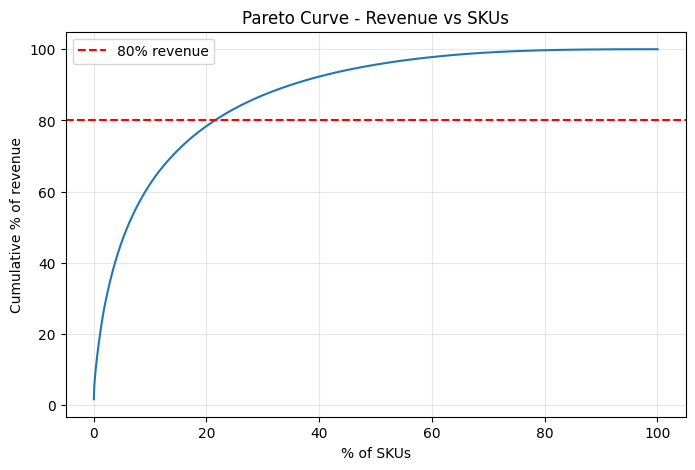

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(sku["sku_pct"] * 100, sku["cum_share"] * 100)
plt.axhline(80, color="red", linestyle="--", label="80% revenue")
plt.xlabel("% of SKUs")
plt.ylabel("Cumulative % of revenue")
plt.title("Pareto Curve - Revenue vs SKUs")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(folder + r"\pareto.png", dpi=150, bbox_inches="tight")             
plt.show()

In [22]:
# month column
data["month"] = data["InvoiceDate"].dt.to_period("M")

# drop Dec 2011, it is only a partial month
monthly = data[data["month"] < pd.Period("2011-12")]

# units sold per SKU per month (0 where no sales)
demand = monthly.pivot_table(index="StockCode", columns="month",
                             values="Quantity", aggfunc="sum", fill_value=0)
print(demand.shape)  # SKUs x 23 months

(4894, 24)


In [23]:
# CV = std / mean of monthly demand (lower = more stable)
cv = demand.std(axis=1) / demand.mean(axis=1)

sku["cv"] = sku["StockCode"].map(cv)

# SKUs with no sales before Dec 2011 have no CV, treat them as erratic
sku["cv"] = sku["cv"].fillna(99)

In [24]:
# X = stable, Y = moderate, Z = erratic
def xyz(c):
    if c <= 0.5:
        return "X"
    elif c <= 1.0:
        return "Y"
    return "Z"

sku["XYZ"] = sku["cv"].apply(xyz)
sku["ABC_XYZ"] = sku["ABC"] + sku["XYZ"]

# SKU count in each cell
print(pd.crosstab(sku["ABC"], sku["XYZ"], margins=True))

# revenue share (%) in each cell
rev = pd.pivot_table(sku, index="ABC", columns="XYZ", values="revenue", aggfunc="sum")
print((rev / rev.sum().sum() * 100).round(1))

XYZ    X    Y     Z   All
ABC                      
A    101  398   551  1050
B     15  236  1029  1280
C      1  135  2428  2564
All  117  769  4008  4894
XYZ     X     Y     Z
ABC                  
A    13.9  36.2  30.0
B     0.2   3.0  11.8
C     0.0   0.4   4.6


In [25]:
# CV only between first and last month of sale (ignores months before launch / after discontinuation)
def active_cv(row):
    nz = np.nonzero(row.values)[0]
    window = row.values[nz[0]:nz[-1] + 1]
    if len(window) < 3:          # too short to judge
        return np.nan
    return window.std(ddof=1) / window.mean()

cv_active = demand.apply(active_cv, axis=1)
sku["cv_active"] = sku["StockCode"].map(cv_active)

print("SKUs with life under 3 months:", sku["cv_active"].isna().sum())

# short-life SKUs are treated as erratic
sku["cv_active"] = sku["cv_active"].fillna(99)

SKUs with life under 3 months: 469


In [26]:
sku["XYZ_adj"] = sku["cv_active"].apply(xyz)

print(pd.crosstab(sku["ABC"], sku["XYZ_adj"], margins=True))

rev = pd.pivot_table(sku, index="ABC", columns="XYZ_adj", values="revenue", aggfunc="sum")
print((rev / rev.sum().sum() * 100).round(1))

XYZ_adj    X     Y     Z   All
ABC                           
A        214   546   290  1050
B        120   501   659  1280
C         85   459  2020  2564
All      419  1506  2969  4894
XYZ_adj     X     Y     Z
ABC                      
A        23.0  40.3  16.6
B         1.6   6.1   7.3
C         0.2   1.2   3.6


In [27]:
# snapshot = last date in the data
snapshot = data["InvoiceDate"].max()
print("Snapshot date:", snapshot)

# days since each SKU last sold
sku["days_since_sale"] = (snapshot - sku["last_sale"]).dt.days

# Dead = no sale in 180+ days, Slow = 90 to 179 days, Active = sold in last 90 days
def status(d):
    if d >= 180:
        return "Dead"
    elif d >= 90:
        return "Slow"
    return "Active"

sku["status"] = sku["days_since_sale"].apply(status)
print(sku["status"].value_counts())

Snapshot date: 2011-12-09 12:50:00
status
Active    3224
Dead      1453
Slow       217
Name: count, dtype: int64


In [28]:
print(pd.crosstab(sku["ABC"], sku["status"], margins=True))

status  Active  Dead  Slow   All
ABC                             
A          966    69    15  1050
B          993   242    45  1280
C         1265  1142   157  2564
All       3224  1453   217  4894


In [29]:
# ASSUMPTIONS - write these in README
cost_ratio = 0.60     # unit cost = 60% of selling price
cover_days = 90       # stock held = 90 days of average demand

# life of each SKU in days (minimum 90, so one-off sales don't give huge daily demand)
life_days = (sku["last_sale"] - sku["first_sale"]).dt.days.clip(lower=90)

sku["daily_demand"] = sku["units"] / life_days
sku["est_stock_units"] = sku["daily_demand"] * cover_days
sku["est_stock_value"] = sku["est_stock_units"] * sku["avg_price"] * cost_ratio

In [30]:
cap = sku.pivot_table(index="ABC", columns="status", values="est_stock_value",
                      aggfunc="sum", fill_value=0)
cap["Total"] = cap.sum(axis=1)
print(cap.round(0))

total = sku["est_stock_value"].sum()
locked = sku.loc[sku["status"].isin(["Dead", "Slow"]), "est_stock_value"].sum()
print("Total est. stock value:", round(total))
print("Locked in dead + slow:", round(locked), f"({locked / total * 100:.1f}%)")

status     Active      Dead     Slow      Total
ABC                                            
A       1545184.0   92690.0  10976.0  1648850.0
B        344917.0  108674.0  10556.0   464147.0
C         95195.0   93292.0   4842.0   193329.0
Total est. stock value: 2306326
Locked in dead + slow: 321030 (13.9%)


In [31]:
# biggest dead A-class items by estimated stock value
dead_a = sku[(sku["ABC"] == "A") & (sku["status"] == "Dead")]
dead_a.sort_values("est_stock_value", ascending=False).head(10)[
    ["StockCode", "description", "revenue", "last_sale", "days_since_sale", "est_stock_value"]]

,StockCode,description,revenue,last_sale,days_since_sale,est_stock_value
144,37503,TEA TIME CAKE STAND IN GIFT BOX,25428.33,2010-08-01 10:09:00,495,5674.090165
660,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,6875.00,2010-02-17 10:51:00,660,4125.000000
243,84467,ENGLISH ROSE DESIGN QUILTED THROW,17477.66,2010-07-27 08:57:00,500,4068.076034
232,79323W,WHITE CHERRY LIGHTS,18048.72,2010-09-16 09:07:00,449,3372.425190
689,85014D,PINK/BROWN DOTS RUFFLED UMBRELLA,6664.45,2010-03-29 14:19:00,619,3049.833051
503,20747,PICCADILLY TEA SET,9224.92,2010-05-16 12:07:00,572,3000.877590
150,21527,RED RETROSPOT TRADITIONAL TEAPOT,24968.47,2011-05-15 16:02:00,207,2543.957321
1043,22833,HALL CABINET WITH 3 DRAWERS,4163.54,2011-02-03 11:39:00,309,2498.124000
287,85232B,SET OF 3 BABUSHKA STACKING TINS,15332.53,2011-02-11 13:53:00,300,1894.637574
370,85042,ANTIQUE LILY FAIRY LIGHTS,12234.56,2010-11-16 12:50:00,388,1887.617829


In [32]:
# calendar month and year of each sale
data["cal_month"] = data["InvoiceDate"].dt.month
data["cal_year"] = data["InvoiceDate"].dt.year

# units sold per SKU in each calendar month
by_month = data.pivot_table(index="StockCode", columns="cal_month",
                            values="Quantity", aggfunc="sum", fill_value=0)

# share of a SKU's units that falls in its 3 best calendar months
top3_share = by_month.apply(lambda r: r.nlargest(3).sum() / r.sum(), axis=1)
years_sold = data.groupby("StockCode")["cal_year"].nunique()

sku["top3_share"] = sku["StockCode"].map(top3_share)
sku["years_sold"] = sku["StockCode"].map(years_sold)

# seasonal = sales bunched in 3 months AND seen in at least 2 different years
sku["seasonal"] = (sku["top3_share"] >= 0.70) & (sku["years_sold"] >= 2)
print(sku["seasonal"].sum(), "seasonal SKUs")

1434 seasonal SKUs


In [33]:
flagged = sku[sku["status"].isin(["Dead", "Slow"])]
print(pd.crosstab(flagged["ABC"], flagged["seasonal"], margins=True))

true_locked = flagged.loc[~flagged["seasonal"], "est_stock_value"].sum()
print("Locked excluding seasonal:", round(true_locked),
      f"({true_locked / total * 100:.1f}% of total)")

seasonal  False  True   All
ABC                        
A            65    19    84
B           163   124   287
C           607   692  1299
All         835   835  1670
Locked excluding seasonal: 155412 (6.7% of total)


In [34]:
for d in [90, 120, 180, 270]:
    v = sku.loc[sku["days_since_sale"] >= d, "est_stock_value"].sum()
    print(f"No sale in {d}+ days: {v / total * 100:.1f}% of est. stock value")

No sale in 90+ days: 13.9% of est. stock value
No sale in 120+ days: 13.5% of est. stock value
No sale in 180+ days: 12.8% of est. stock value
No sale in 270+ days: 10.9% of est. stock value


In [35]:
# seasonal needs at least ~1 year of history and enough orders to judge a pattern
life_full = (sku["last_sale"] - sku["first_sale"]).dt.days
sku["seasonal_strict"] = (sku["top3_share"] >= 0.70) & (life_full >= 330) & (sku["orders"] >= 6)

print(sku["seasonal_strict"].sum(), "seasonal SKUs (strict)")

891 seasonal SKUs (strict)


In [36]:
flagged = sku[sku["status"].isin(["Dead", "Slow"])]
print(pd.crosstab(flagged["ABC"], flagged["seasonal_strict"], margins=True))

locked_strict = flagged.loc[~flagged["seasonal_strict"], "est_stock_value"].sum()
print("Locked excluding strict seasonal:", round(locked_strict),
      f"({locked_strict / total * 100:.1f}% of total)")

seasonal_strict  False  True   All
ABC                               
A                   76     8    84
B                  237    50   287
C                 1041   258  1299
All               1354   316  1670
Locked excluding strict seasonal: 290034 (12.6% of total)


In [37]:
def strategy(r):
    # dead or slow items
    if r["status"] in ["Dead", "Slow"]:
        if r["seasonal_strict"]:
            return "Seasonal - order to forecast before season"
        if r["ABC"] == "A":
            return "Former top seller - check why it stopped, clear remaining stock"
        return "Delist and liquidate"
    # active items
    if r["ABC"] == "A":
        return {"X": "Tight control, frequent replenishment, low safety stock",
                "Y": "Regular review, moderate safety stock",
                "Z": "Higher safety stock, monitor demand closely"}[r["XYZ_adj"]]
    if r["ABC"] == "B":
        return "Standard reorder point, periodic review" if r["XYZ_adj"] != "Z" \
               else "Small batches, review range"
    return "Bulk and infrequent ordering" if r["XYZ_adj"] != "Z" \
           else "Order on demand, consider cutting from range"

sku["strategy"] = sku.apply(strategy, axis=1)
print(sku["strategy"].value_counts())

strategy
Delist and liquidate                                               1278
Order on demand, consider cutting from range                        986
Standard reorder point, periodic review                             501
Regular review, moderate safety stock                               500
Small batches, review range                                         492
Seasonal - order to forecast before season                          316
Bulk and infrequent ordering                                        279
Higher safety stock, monitor demand closely                         261
Tight control, frequent replenishment, low safety stock             205
Former top seller - check why it stopped, clear remaining stock      76
Name: count, dtype: int64


In [38]:
# ASSUMPTIONS - write in README
recovery_rate = 0.50      # cash recovered on liquidated stock
cover_x_new = 60          # new cover days for stable active items

# 1. liquidation of dead/slow non-seasonal stock
liq = sku[sku["strategy"].isin(["Delist and liquidate",
          "Former top seller - check why it stopped, clear remaining stock"])]
freed_liq = liq["est_stock_value"].sum() * recovery_rate

# 2. lower cover on stable active items
stable = sku[(sku["status"] == "Active") & (sku["XYZ_adj"] == "X")]
freed_cover = stable["est_stock_value"].sum() * (1 - cover_x_new / cover_days)

print("Liquidation:", round(freed_liq))
print("Lower cover on X items:", round(freed_cover))
print("Total capital freed:", round(freed_liq + freed_cover),
      f"({(freed_liq + freed_cover) / total * 100:.1f}% of est. stock value)")

Liquidation: 145017
Lower cover on X items: 186209
Total capital freed: 331226 (14.4% of est. stock value)


In [39]:
strat_sum = sku.groupby("strategy").agg(
    skus=("StockCode", "count"),
    revenue=("revenue", "sum"),
    est_stock_value=("est_stock_value", "sum"),
).round(0).sort_values("est_stock_value", ascending=False)
strat_sum

,skus,revenue,est_stock_value
strategy,,,
"Regular review, moderate safety stock",500,7462376.0,729646.0
"Tight control, frequent replenishment, low safety stock",205,4395664.0,465185.0
"Higher safety stock, monitor demand closely",261,3005458.0,350353.0
"Standard reorder point, periodic review",501,1218312.0,219719.0
Delist and liquidate,1278,813016.0,194623.0
"Small batches, review range",492,1076326.0,125198.0
"Former top seller - check why it stopped, clear remaining stock",76,591320.0,95411.0
"Order on demand, consider cutting from range",986,411988.0,56352.0
Bulk and infrequent ordering,279,169635.0,38843.0


In [40]:
sku.to_csv(folder + r"\sku_analysis.csv", index=False)
print("Saved", sku.shape)

Saved (4894, 27)


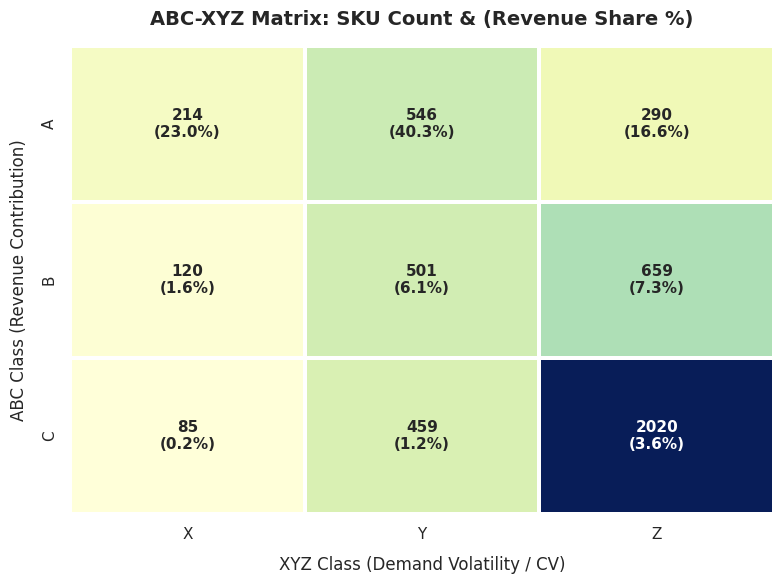

In [41]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})

# ABC-XYZ 3x3 HEATMAP VISUALIZATION
# Pivot tables for SKU counts and Revenue Share %
sku_matrix = pd.pivot_table(sku, index="ABC", columns="XYZ_adj", values="StockCode", aggfunc="count", fill_value=0)
rev_matrix = pd.pivot_table(sku, index="ABC", columns="XYZ_adj", values="revenue", aggfunc="sum", fill_value=0)
rev_share_matrix = (rev_matrix / rev_matrix.sum().sum() * 100).round(1)

# Combined text labels: "Count (Revenue %)"
annot_matrix = sku_matrix.astype(str) + "\n(" + rev_share_matrix.astype(str) + "%)"

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(sku_matrix, annot=annot_matrix, fmt="", cmap="YlGnBu", cbar=False,
            linewidths=1.5, linecolor='white', annot_kws={"size": 11, "weight": "bold"}, ax=ax)

ax.set_title("ABC-XYZ Matrix: SKU Count & (Revenue Share %)", fontsize=14, pad=15, weight='bold')
ax.set_xlabel("XYZ Class (Demand Volatility / CV)", fontsize=12, labelpad=10)
ax.set_ylabel("ABC Class (Revenue Contribution)", fontsize=12, labelpad=10)
plt.tight_layout()
plt.savefig(folder + r"\abc_xyz_heatmap.png", dpi=150, bbox_inches="tight")    
plt.show()


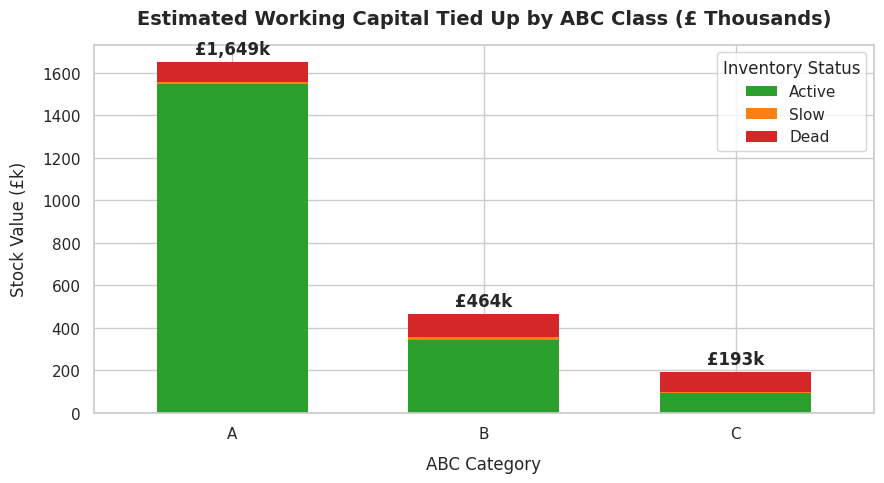

In [42]:
#  WORKING CAPITAL BREAKDOWN CHART
cap_summary = sku.groupby(["ABC", "status"])["est_stock_value"].sum().unstack(fill_value=0) / 1e3  # In Thousands

fig, ax = plt.subplots(figsize=(9, 5))
cap_summary[["Active", "Slow", "Dead"]].plot(kind="bar", stacked=True, 
                                           color=["#2ca02c", "#ff7f0e", "#d62728"], 
                                           ax=ax, edgecolor="none", width=0.6)

ax.set_title("Estimated Working Capital Tied Up by ABC Class (£ Thousands)", fontsize=14, pad=15, weight='bold')
ax.set_xlabel("ABC Category", fontsize=12, labelpad=10)
ax.set_ylabel("Stock Value (£k)", fontsize=12, labelpad=10)
ax.legend(title="Inventory Status", frameon=True)
plt.xticks(rotation=0)

# Add total values on top of bars
for i, total in enumerate(cap_summary.sum(axis=1)):
    ax.text(i, total + 20, f"£{total:,.0f}k", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(folder + r"\capital_by_class.png", dpi=150, bbox_inches="tight") 
plt.show()

In [43]:
# SAFETY STOCK & REORDER POINT (ROP)
# Assumptions: lead time = 14 days; service levels A=98% (Z=2.05), B=95% (Z=1.65), C=90% (Z=1.28)
lead_time_days = 14
z_scores = {"A": 2.05, "B": 1.65, "C": 1.28}

# only active SKUs with a real CV (exclude the 99 placeholder)
active_skus = sku[(sku["status"] == "Active") & (sku["cv_active"] < 99)].copy()

active_skus["z_score"] = active_skus["ABC"].map(z_scores)

# monthly demand and its std (CV is monthly, so keep units monthly)
monthly_demand = active_skus["daily_demand"] * 30
monthly_std = monthly_demand * active_skus["cv_active"]

# std over the lead time = monthly std * sqrt(lead time in months)
std_lead_time = monthly_std * np.sqrt(lead_time_days / 30)

# Safety stock = Z * std over lead time
active_skus["safety_stock_units"] = np.ceil(active_skus["z_score"] * std_lead_time)

# ROP = demand during lead time + safety stock
active_skus["rop_units"] = np.ceil(active_skus["daily_demand"] * lead_time_days
                                   + active_skus["safety_stock_units"])

In [44]:
# Merge ROP back into main SKU dataframe
sku["safety_stock_units"] = sku["StockCode"].map(active_skus.set_index("StockCode")["safety_stock_units"]).fillna(0)
sku["rop_units"] = sku["StockCode"].map(active_skus.set_index("StockCode")["rop_units"]).fillna(0)


In [45]:
# Save updated dataset
sku.to_csv(folder + r"\sku_analysis_final.csv", index=False)
print("Updated dataframe with ROP and Safety Stock saved successfully!")

Updated dataframe with ROP and Safety Stock saved successfully!


In [46]:
sku[["safety_stock_units", "rop_units"]].describe()

,safety_stock_units,rop_units
count,4894.000000,4894.000000
mean,114.719248,168.683490
std,299.988737,414.261929
min,0.000000,0.000000
25%,0.000000,0.000000
50%,13.000000,19.000000
75%,114.000000,167.000000
max,8594.000000,10624.000000


In [47]:
# stats for SKUs that actually have a reorder point
has_rop = sku[sku["rop_units"] > 0]
print(len(has_rop), "SKUs with a reorder point")
print(has_rop[["safety_stock_units", "rop_units"]].describe())

# top 10 by safety stock, with their demand and variability
cols = ["StockCode", "description", "ABC", "XYZ_adj", "cv_active",
        "daily_demand", "safety_stock_units", "rop_units"]
sku.sort_values("safety_stock_units", ascending=False).head(10)[cols]

3061 SKUs with a reorder point
       safety_stock_units     rop_units
count         3061.000000   3061.000000
mean           183.415877    269.695198
std            362.348988    497.153085
min              1.000000      2.000000
25%             20.000000     31.000000
50%             77.000000    114.000000
75%            204.000000    302.000000
max           8594.000000  10624.000000


,StockCode,description,ABC,XYZ_adj,cv_active,daily_demand,safety_stock_units,rop_units
13,23084,RABBIT NIGHT LIGHT,A,Z,1.410765,144.995283,8594.0,10624.0
301,17003,BROCADE RING PURSE,A,Z,1.110575,95.480326,4455.0,5792.0
7,22197,POPCORN HOLDER,A,Y,0.823826,119.917344,4151.0,5830.0
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,A,Z,2.123892,42.559621,3798.0,4394.0
219,22952,60 CAKE CASES VINTAGE CHRISTMAS,A,Z,1.132434,73.798658,3512.0,4546.0
447,21982,PACK OF 12 SUKI TISSUES,A,Z,1.877889,43.893297,3463.0,4078.0
634,21981,PACK OF 12 WOODLAND TISSUES,A,Z,2.226564,35.603261,3331.0,3830.0
642,21984,PACK OF 12 PINK PAISLEY TISSUES,A,Z,2.243998,34.444293,3248.0,3731.0
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,A,Z,1.619292,47.539295,3235.0,3901.0
155,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,A,Y,0.518622,144.014925,3138.0,5155.0


In [48]:
sku[sku["StockCode"] == "37410"][["StockCode", "description", "ABC", "units", "orders",
                                  "avg_price", "first_sale", "last_sale", "est_stock_value"]]

,StockCode,description,ABC,units,orders,avg_price,first_sale,last_sale,est_stock_value
1242,37410,BLACK AND WHITE PAISLEY FLOWER MUG,B,25707,33,0.127928,2009-12-01 12:19:00,2010-04-07 14:10:00,1398.323622


In [49]:
data[data["StockCode"] == "37410"].sort_values("Revenue", ascending=False).head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,month,cal_month,cal_year
86730,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,1915.20,2010-02,2,2010
62366,495194,37410,BLACK AND WHITE PAISLEY FLOWER MUG,6012,2010-01-21 15:11:00,0.10,13902.0,Denmark,601.20,2010-01,1,2010
874,489542,37410,BLACK AND WHITE PAISLEY FLOWER MUG,216,2009-12-01 12:19:00,0.85,15061.0,United Kingdom,183.60,2009-12,12,2009
21315,491148,37410,BLACK AND WHITE PAISLEY FLOWER MUG,72,2009-12-10 07:43:00,1.06,15061.0,United Kingdom,76.32,2009-12,12,2009
100648,499486,37410,BLACK AND WHITE PAISLEY FLOWER MUG,72,2010-02-28 13:42:00,0.85,15061.0,United Kingdom,61.20,2010-02,2,2010
65508,495406,37410,BLACK AND WHITE PAISLEY FLOWER MUG,3,2010-01-25 09:54:00,16.13,NaN,United Kingdom,48.39,2010-01,1,2010
144400,503806,37410,BLACK AND WHITE PAISLEY FLOWER MUG,48,2010-04-07 14:10:00,0.85,15061.0,United Kingdom,40.80,2010-04,4,2010
19223,491041,37410,BLACK AND WHITE PAISLEY FLOWER MUG,1,2009-12-09 09:42:00,16.48,NaN,United Kingdom,16.48,2009-12,12,2009
2414,489601,37410,BLACK AND WHITE PAISLEY FLOWER MUG,1,2009-12-01 14:44:00,16.48,NaN,United Kingdom,16.48,2009-12,12,2009
42580,493273,37410,BLACK AND WHITE PAISLEY FLOWER MUG,1,2009-12-22 15:09:00,16.48,NaN,United Kingdom,16.48,2009-12,12,2009


In [50]:
sku[sku["StockCode"] == "37410"][["units", "revenue", "avg_price", "est_stock_value"]]

,units,revenue,avg_price,est_stock_value
1242,25707,3288.65,0.127928,1398.323622


In [51]:
total = sku["est_stock_value"].sum()
flagged = sku[sku["status"].isin(["Dead", "Slow"])]
locked = flagged["est_stock_value"].sum()
locked_strict = flagged.loc[~flagged["seasonal_strict"], "est_stock_value"].sum()

print("Total est. stock value:", round(total))
print("Locked in dead + slow:", round(locked), f"({locked / total * 100:.1f}%)")
print("Locked excl. strict seasonal:", round(locked_strict), f"({locked_strict / total * 100:.1f}%)")

recovery_rate, cover_x_new = 0.50, 60
liq = sku[sku["strategy"].isin(["Delist and liquidate",
          "Former top seller - check why it stopped, clear remaining stock"])]
freed_liq = liq["est_stock_value"].sum() * recovery_rate
stable = sku[(sku["status"] == "Active") & (sku["XYZ_adj"] == "X")]
freed_cover = stable["est_stock_value"].sum() * (1 - cover_x_new / 90)
print("Liquidation:", round(freed_liq))
print("Lower cover on X items:", round(freed_cover))
print("Total capital freed:", round(freed_liq + freed_cover), f"({(freed_liq + freed_cover) / total * 100:.1f}%)")

for d in [90, 120, 180, 270]:
    v = sku.loc[sku["days_since_sale"] >= d, "est_stock_value"].sum()
    print(f"No sale in {d}+ days: {v / total * 100:.1f}%")

Total est. stock value: 2306326
Locked in dead + slow: 321030 (13.9%)
Locked excl. strict seasonal: 290034 (12.6%)
Liquidation: 145017
Lower cover on X items: 186209
Total capital freed: 331226 (14.4%)
No sale in 90+ days: 13.9%
No sale in 120+ days: 13.5%
No sale in 180+ days: 12.8%
No sale in 270+ days: 10.9%


In [52]:
cap = sku.pivot_table(index="ABC", columns="status", values="est_stock_value",
                      aggfunc="sum", fill_value=0)
cap["Total"] = cap.sum(axis=1)
print(cap.round(0))

status     Active      Dead     Slow      Total
ABC                                            
A       1545184.0   92690.0  10976.0  1648850.0
B        344917.0  108674.0  10556.0   464147.0
C         95195.0   93292.0   4842.0   193329.0
